## Escalon y rampa

El escalón unitario $u[n]$ o $u(t)$ y la rampa unitaria $r[n]$ o $r(t)$ están directamente conectados entre sí: la rampa es simplemente el eje de tiempo multiplicado por el escalón ($r[n] = n \cdot u[n]$), o vista desde la electrónica y el cálculo, la rampa es el resultado de integrar una forma de onda escalón constante en el tiempo.  

- Escalón unitario ($u[n]$): Vale $0$ para $n < 0$ y $1$ para $n \ge 0$.
- Rampa unitaria ($r[n]$): Vale $0$ para $n < 0$ y $n$ para $n \ge 0$.

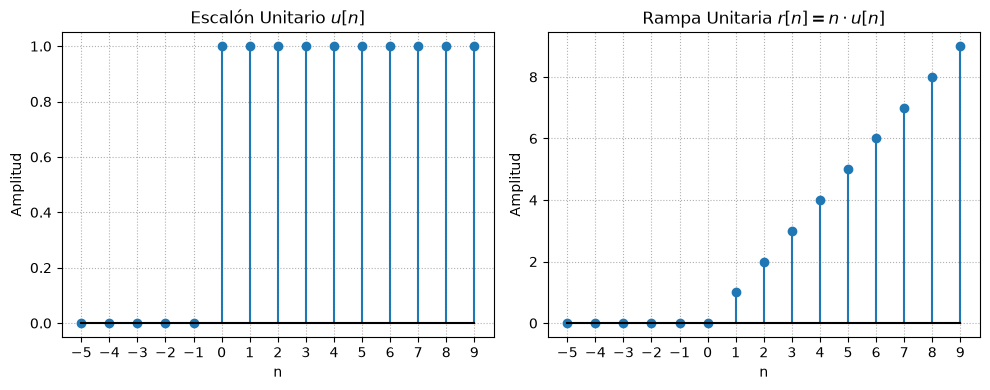

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 10)          # Muestras de -5 a 9

u = (n >= 0) * 1               # Escalón unitario u[n]
r = n * (n >= 0)               # Rampa unitaria r[n] = n * u[n]

plt.figure(figsize=(10, 4))

# Gráfica del Escalón
plt.subplot(1, 2, 1)
plt.stem(n, u, basefmt="k-")
plt.title('Escalón Unitario $u[n]$')
plt.xlabel('n'); plt.ylabel('Amplitud')
plt.xticks(n); plt.grid(True, linestyle=':')

# Gráfica de la Rampa
plt.subplot(1, 2, 2)
plt.stem(n, r, basefmt="k-")
plt.title(r'Rampa Unitaria $r[n] = n \cdot u[n]$')
plt.xlabel('n'); plt.ylabel('Amplitud')
plt.xticks(n); plt.grid(True, linestyle=':')

plt.tight_layout()
plt.show()

## Usando sympy

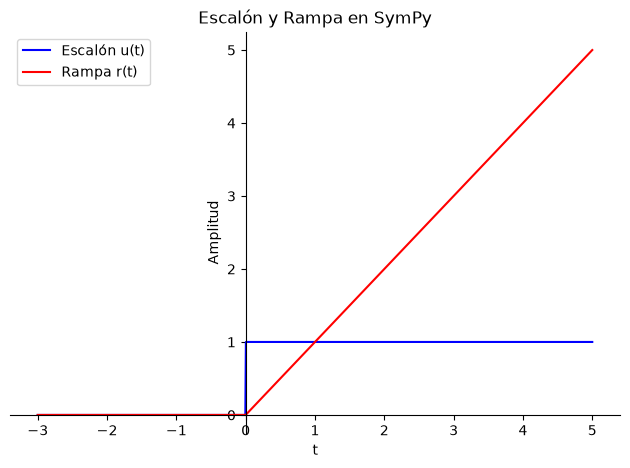

In [2]:
import sympy as sp

t = sp.symbols('t', real=True)

# 1. Definir Escalón y Rampa en SymPy
u_sym = sp.Heaviside(t)        # Escalón u(t)
r_sym = t * sp.Heaviside(t)    # Rampa r(t) = t * u(t)

# 2. Graficar ambas en el intervalo de -3 a 5
p = sp.plot(u_sym, r_sym, (t, -3, 5), 
            title='Escalón y Rampa en SymPy',
            xlabel='t', ylabel='Amplitud', 
            legend=True, show=False)

p[0].line_color = 'blue'
p[0].label = 'Escalón u(t)'
p[1].line_color = 'red'
p[1].label = 'Rampa r(t)'
p.show()

# onda diente de sierra (sawtooth) y la onda triangular

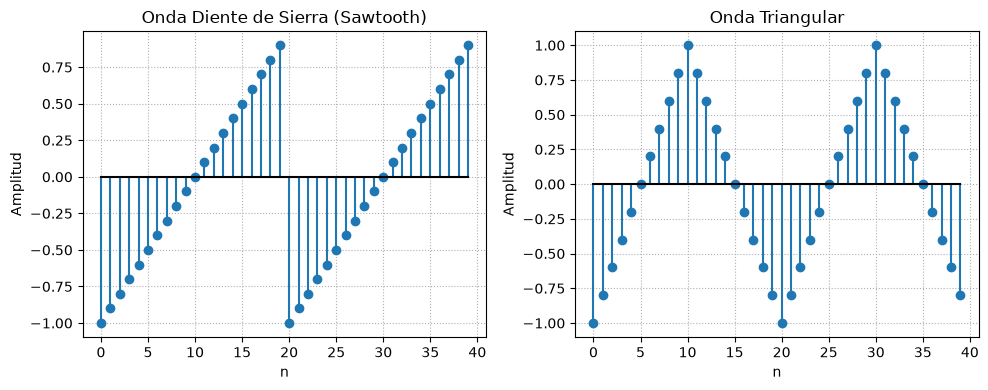

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Vector de muestras discretas (2 periodos de N = 20 muestras cada uno)
N = 20
n = np.arange(0, 40)

# Diente de sierra (width=1) y Triangular (width=0.5)
saw = signal.sawtooth(2 * np.pi * n / N, width=1.0)
tri = signal.sawtooth(2 * np.pi * n / N, width=0.5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.stem(n, saw, basefmt="k-")
plt.title('Onda Diente de Sierra (Sawtooth)')
plt.xlabel('n'); plt.ylabel('Amplitud'); plt.grid(True, linestyle=':')

plt.subplot(1, 2, 2)
plt.stem(n, tri, basefmt="k-")
plt.title('Onda Triangular')
plt.xlabel('n'); plt.ylabel('Amplitud'); plt.grid(True, linestyle=':')

plt.tight_layout()
plt.show()

## En SymPy puro

e:\PROJECTS\ISB_COURSE\.venv\Lib\site-packages\sympy\plotting\series.py:539: UserWarning: NumPy is unable to evaluate with complex numbers some of the functions included in this symbolic expression: [floor]. Hence, the evaluation will use real numbers. If you believe the resulting plot is incorrect, change the evaluation module by setting the `modules` keyword argument.
  warnings.warn("NumPy is unable to evaluate with complex "


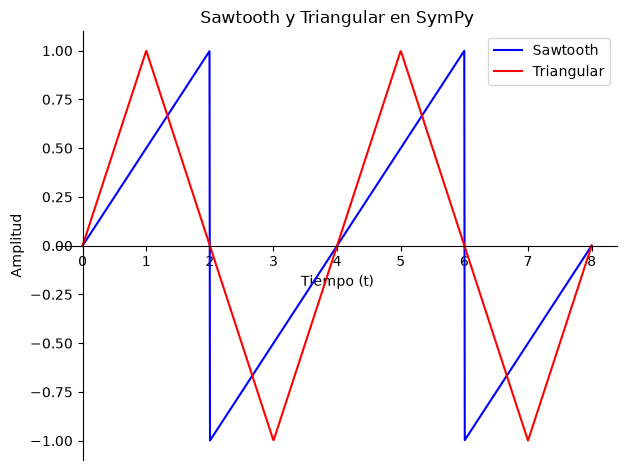

In [6]:
import sympy as sp

t = sp.symbols('t', real=True)
T = 4  # Periodo de la señal (ej. 4 segundos)

# 1. Ecuación simbólica de Diente de Sierra y Triangular (oscilan entre -1 y 1)
saw_sym = 2 * (t / T - sp.floor(t / T + sp.Rational(1, 2)))
tri_sym = (2 / sp.pi) * sp.asin(sp.sin(2 * sp.pi * t / T))

# 2. Graficar en SymPy de t = 0 a t = 8 (2 periodos)
p = sp.plot(saw_sym, tri_sym, (t, 0, 8), 
            title='Sawtooth y Triangular en SymPy',
            xlabel='Tiempo (t)', ylabel='Amplitud', 
            legend=True, show=False)

p[0].line_color = 'blue'
p[0].label = 'Sawtooth'
p[1].line_color = 'red'
p[1].label = 'Triangular'
p.show()